In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

df = pd.read_csv("../data/diabetes.csv")   # <- your file name
TARGET = "Outcome"   
columns_with_fake_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

plot_df = df.copy()
for col in columns_with_fake_zeros:
    plot_df[col] = plot_df[col].replace(0,np.nan)

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [2]:
print("Duplicated rows:", df.duplicated().sum())
print("Total NaN cells:", df.isna().sum().sum())

Duplicated rows: 0
Total NaN cells: 0


In [3]:
# Class Imbalance

counts=df["Outcome"].value_counts()
print(f"Counts: {counts}")


percent=df["Outcome"].value_counts(normalize=True)*100
print(f"Percentage: {percent}")



Counts: Outcome
0    500
1    268
Name: count, dtype: int64
Percentage: Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


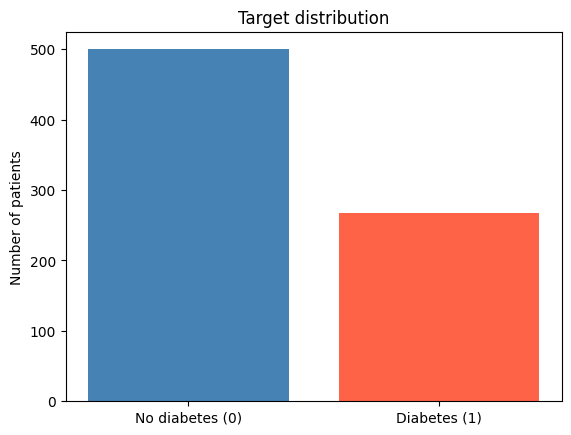

In [4]:
# How many patients have and don’t have diabetes

plt.bar(["No diabetes (0)","Diabetes (1)"], [counts[0], counts[1]],color=["steelblue", "tomato"])
plt.title("Target distribution")
plt.ylabel("Number of patients")
plt.show()

#500 vs 268 (65% / 35%), moderately imbalanced, so accuracy alone can mislead


















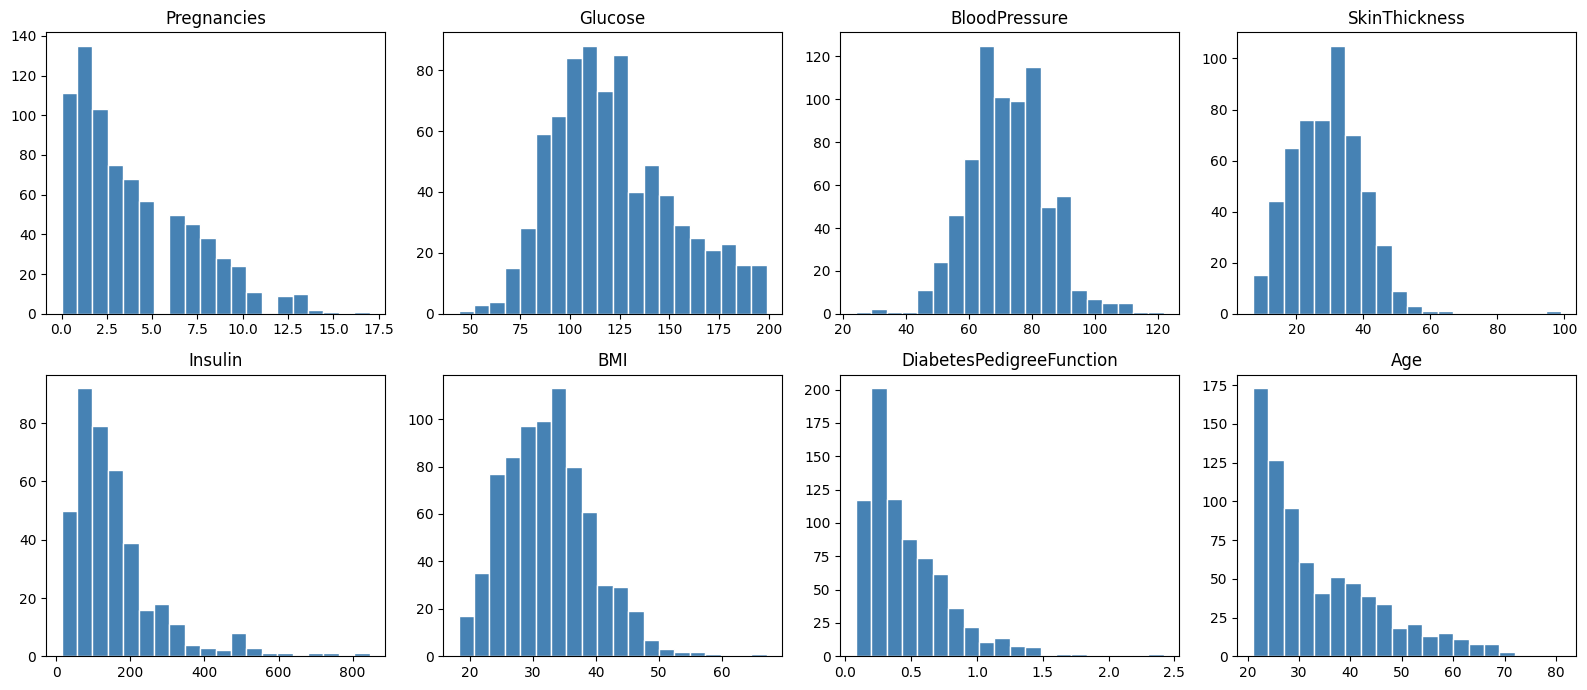

In [5]:
#The shape and range of each feature


plt.figure(figsize=(16, 7))

for i in range(len(features)):
    plt.subplot(2, 4, i + 1)
    plt.hist(plot_df[features[i]].dropna(), bins=20, color="steelblue", edgecolor="white")
    plt.title(features[i])

plt.tight_layout()
plt.show()

# Insulin and DiabetesPedigreeFunction are strongly right-skewed.
#Age leans young. Glucose, BloodPressure and BMI are roughly bell-shaped

AgeGroup
21-30    21.6
31-40    48.4
41-50    56.6
51+      46.9
Name: Outcome, dtype: float64


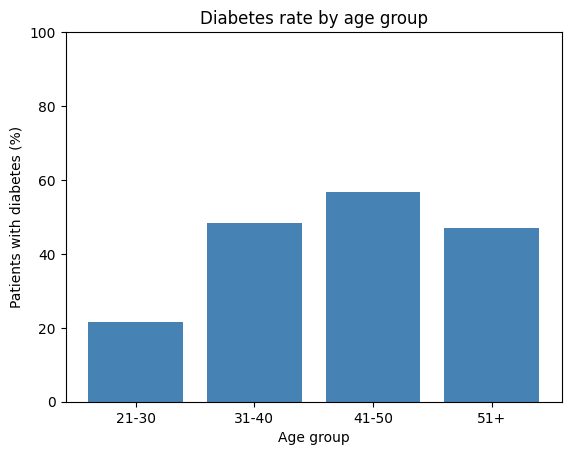

In [6]:
# The percentage with diabetes in each age band


plot_df["AgeGroup"] = pd.cut(plot_df["Age"],
                             bins=[20, 30, 40, 50, 100],
                             labels=["21-30", "31-40", "41-50", "51+"])

rate = plot_df.groupby("AgeGroup", observed=True)["Outcome"].mean() * 100
print(rate.round(1))

plt.bar(rate.index.astype(str), rate.values, color="steelblue")
plt.title("Diabetes rate by age group")
plt.xlabel("Age group")
plt.ylabel("Patients with diabetes (%)")
plt.ylim(0, 100)
plt.show()


#Rises from 21.6% (21-30) to 56.6% (41-50), then dips to 46.9% for 51+ (a small group)



BMIGroup
Underweight     0.0
Normal          6.5
Overweight     24.4
Obese          46.2
Name: Outcome, dtype: float64


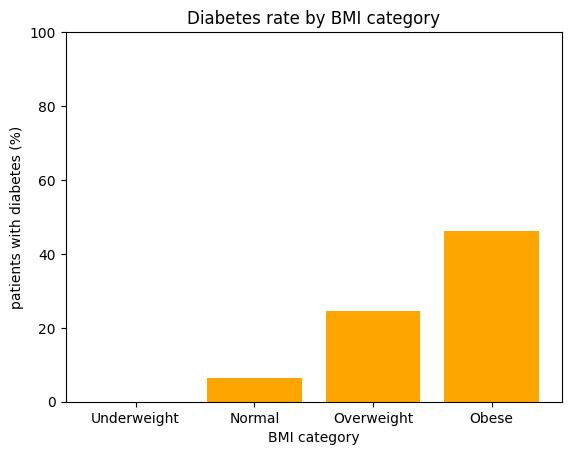

In [7]:
# diabetes rate by BMI category

plot_df["BMIGroup"]=pd.cut(plot_df["BMI"],
                           bins=[0,18.5,25,30,100],
                           labels=["Underweight", "Normal", "Overweight", "Obese"])


rate=plot_df.groupby("BMIGroup", observed=True)["Outcome"].mean()*100
print(rate.round(1))

plt.bar(rate.index.astype(str), rate.values, color="orange")
plt.title("Diabetes rate by BMI category")
plt.xlabel("BMI category")
plt.ylabel("patients with diabetes (%)")
plt.ylim(0,100)
plt.show()

# Rises steadily: 6.5% normal, 24.4% overweight, 46.2% obese

GlucoseGroup
100 or less     8.6
101-125        28.0
126-150        45.2
over 150       75.0
Name: Outcome, dtype: float64


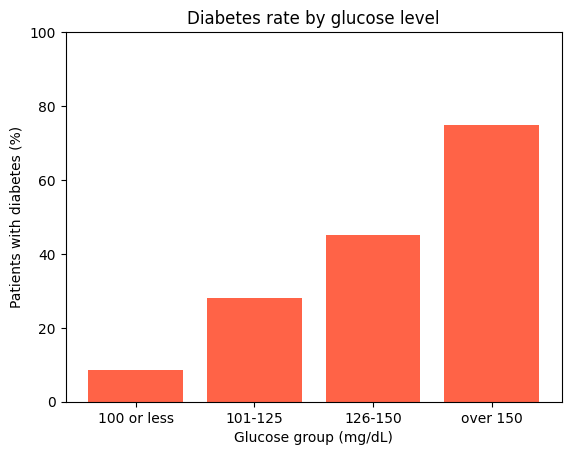

In [8]:
#The percentage with diabetes in each glucose band

plot_df["GlucoseGroup"]=pd.cut(plot_df["Glucose"],
                               bins=[0,100,125,150,250],
                               labels=["100 or less", "101-125", "126-150", "over 150"])


rate=plot_df.groupby("GlucoseGroup",observed=True)["Outcome"].mean()*100
print(rate.round(1))

plt.bar(rate.index.astype(str), rate.values, color="tomato")
plt.title("Diabetes rate by glucose level")
plt.xlabel("Glucose group (mg/dL)")
plt.ylabel("Patients with diabetes (%)")
plt.ylim(0,100)
plt.show();

# The steepest rise: 8.6% at 100 or less, up to 75% above 150


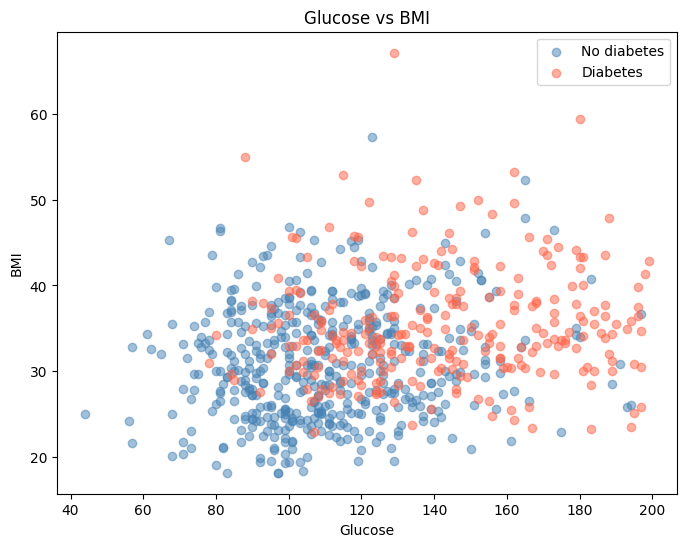

In [9]:
no_diab = plot_df[plot_df["Outcome"] == 0]
diab = plot_df[plot_df["Outcome"] == 1]

plt.figure(figsize=(8, 6))
plt.scatter(no_diab["Glucose"], no_diab["BMI"], alpha=0.5, label="No diabetes", color="steelblue")
plt.scatter(diab["Glucose"], diab["BMI"], alpha=0.5, label="Diabetes", color="tomato")
plt.title("Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.show()

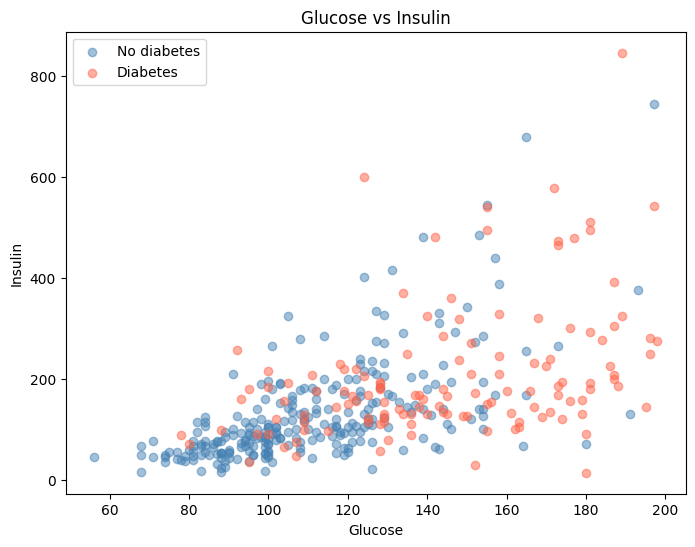

In [10]:
#Whether the two features move together


no_diab=plot_df[plot_df["Outcome"]==0]
diab=plot_df[plot_df["Outcome"]==1]

plt.figure(figsize=(8,6))

plt.scatter(no_diab["Glucose"], no_diab["Insulin"], alpha=0.5, label="No diabetes", color="steelblue")

plt.scatter(diab["Glucose"], diab["Insulin"], alpha=0.5, label="Diabetes", color="tomato")

plt.title("Glucose vs Insulin")
plt.xlabel("Glucose")
plt.ylabel("Insulin")
plt.legend()
plt.show()

# They do (correlation 0.58). Only about 393 patients are plotted because many Insulin values are missing

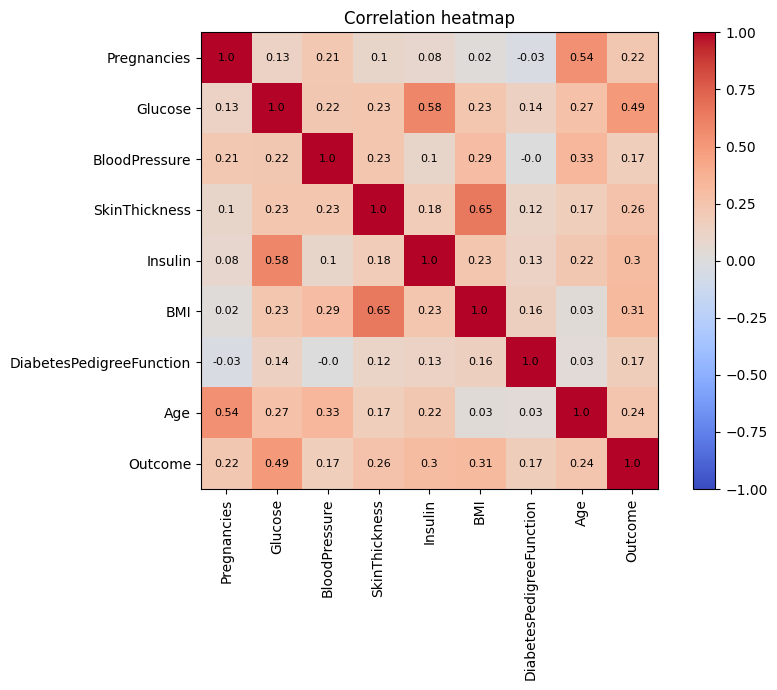

In [13]:
# correlation of every pair of features

corr = plot_df[features + ["Outcome"]].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center", fontsize=8)

plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

#Glucose is the strongest link with Outcome (0.49). Some features overlap, like SkinThickness with BMI (0.65)
